# Frozen Hallmark-state retrieval from TCGA into ARCHS4

## Scientific question

Can the frozen Bridge sample representation support two distinct search modes over ARCHS4: global similarity in the original 512-dimensional representation and interpretable functional-state similarity after projection into 50 Hallmark programs?

The hypothesis is that the frozen Hallmark projection will preserve pathway-profile similarity while retrieving a neighborhood that only partly overlaps the global Bridge neighborhood. The comparison is not designed to establish that either search mode is universally superior.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
PACKAGE = Path.cwd()
if not (PACKAGE / "data").exists():
    PACKAGE = Path("notebooks/tcga_archs4_state_retrieval").resolve()
DATA = PACKAGE / "data"
FIGURES = PACKAGE / "figures"
FIGURES.mkdir(exist_ok=True)

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    plt.show()

individual = pd.read_csv(DATA / "individual_method_overlap.csv")
centroid = pd.read_csv(DATA / "centroid_method_overlap.csv")
preservation = pd.read_csv(DATA / "functional_profile_preservation.csv")
expression = pd.read_csv(DATA / "expression_subset_method_overlap.csv")
metadata = pd.read_csv(DATA / "metadata_coherence.csv")
dominant = pd.read_csv(DATA / "dominant_pathway_removal_summary.csv")
pathways = pd.read_csv(DATA / "pathway_wise_preservation.csv")
query_profiles = pd.read_csv(DATA / "tcga_centroid_hallmark_profiles.csv", index_col=0)
retrieved_profiles = pd.read_csv(DATA / "retrieved_archs4_mean_hallmark_profiles.csv", index_col=0)
qa = json.loads((DATA / "qa.json").read_text())
headline = json.loads((DATA / "headline_summary.json").read_text())

assert qa["passed"] is True
assert qa["dimensions"] == {
    "archs4_bridge": [510709, 512], "tcga_bridge": [9816, 512],
    "archs4_hallmark": [510709, 50], "tcga_hallmark": [9816, 50]
}
assert len(individual) == 9816 * 6 and individual.query_index.nunique() == 9816
assert len(centroid) == 32 * 6 and centroid.cancer_type.nunique() == 32
assert query_profiles.shape == retrieved_profiles.shape == (32, 50)
assert np.isfinite(query_profiles.to_numpy()).all()
assert np.isfinite(retrieved_profiles.to_numpy()).all()
print("Cached evidence loaded; cohort, dimensions, ordering, and finite-value checks passed.")

Cached evidence loaded; cohort, dimensions, ordering, and finite-value checks passed.


## Data and frozen Hallmark readout

The query cohort contains **9,816 TCGA primary tumors**, one specimen per patient, spanning **32 cancer types**. The reference database contains **510,709 unique human ARCHS4 samples**. Bridge inputs use natural `log1p(TPM)` in the exact canonical 15,165-gene order. Bridge remains frozen, and its sample embedding is the unweighted mean of final-layer contextual gene states.

The Hallmark head was trained previously using **4,260 GTEx samples from 920 donors and 12 broad tissues**:

1. Rank all 15,165 genes within each GTEx sample and divide each rank by 15,165.
2. For each of 50 MSigDB Hallmarks, average the normalized ranks of its canonical member genes.
3. Standardize each expression-derived Hallmark target across GTEx.
4. Standardize the 512 Bridge coordinates using GTEx training means and standard deviations.
5. Fit a 50-output Ridge model with one global penalty selected from `0.01, 0.1, 1, 10, 100` by five-fold donor-grouped cross-validation. The selected penalty was `alpha=0.1`; the final scaler and model were refit on all GTEx samples and frozen.

For an unseen sample with Bridge embedding $z$, inference is

$$
P(z) = \left(\frac{z-\mu_{GTEx}}{\sigma_{GTEx}}\right)W^T + b.
$$

The outputs are continuous **Bridge Hallmark scores** predicting GTEx-standardized rank-mean targets. They are not probabilities, GSEA enrichment scores, formal ssGSEA scores, causal pathway activities, or gene-level decoder outputs. Neither TCGA nor ARCHS4 labels were used to fit this mapping.

## Retrieval protocol

Every TCGA patient independently queried the complete ARCHS4 reference collection, and each of the 32 cancer types also supplied a centroid query. The same query definitions were used for:

- **Bridge-512:** cosine similarity in the frozen sample representation.
- **Hallmark-50:** cosine similarity between the frozen 50-dimensional Bridge Hallmark profiles.

Top 1, 5, 10, 25, 50, and 100 neighbors were retained. The methods were compared by overlap count, Jaccard similarity, shared-candidate rank correlation, metadata keyword coherence, study diversity, pathway-profile preservation, dominant-pathway removal, and universal-neighbor frequency.

A conventional expression baseline used the same 32 cancer centroids and a deterministic 40,000-sample ARCHS4 subset represented by the exact 15,165-gene natural `log1p(TPM)` matrix. Bridge, Hallmark, and expression retrieval were recomputed on this identical candidate universe. The expression comparison is therefore centroid-only and subset-scoped.

In [2]:
i100 = individual[individual.k.eq(100)]
c100 = centroid[centroid.k.eq(100)]
summary = pd.DataFrame({
    "query mode": ["Individual TCGA samples", "Cancer centroids"],
    "queries": [i100.query_index.nunique(), c100.query_index.nunique()],
    "median overlap@100": [i100.overlap_count.median(), c100.overlap_count.median()],
    "median Jaccard@100": [i100.jaccard.median(), c100.jaccard.median()],
    "Jaccard IQR low": [i100.jaccard.quantile(.25), c100.jaccard.quantile(.25)],
    "Jaccard IQR high": [i100.jaccard.quantile(.75), c100.jaccard.quantile(.75)],
})
assert np.isclose(summary.loc[0, "median Jaccard@100"], headline["individual_bridge_hallmark_jaccard100_median"])
assert np.isclose(summary.loc[1, "median Jaccard@100"], headline["centroid_bridge_hallmark_jaccard100_median"])
display(summary.round({
    "median overlap@100": 0, "median Jaccard@100": 3,
    "Jaccard IQR low": 3, "Jaccard IQR high": 3
}))

,query mode,queries,median overlap@100,median Jaccard@100,Jaccard IQR low,Jaccard IQR high
0,Individual TCGA samples,9816,20.0,0.111,0.064,0.176
1,Cancer centroids,32,22.0,0.124,0.093,0.220


## Hallmark retrieval identifies a distinct neighborhood

The two frozen representations produced markedly different nearest-neighbor sets. Individual-query Bridge/Hallmark overlap was **20 of 100 samples at the median**, corresponding to median Jaccard **0.111** (IQR **0.064–0.176**). Cancer-centroid overlap was **22 of 100**, with median Jaccard **0.124** (IQR **0.093–0.220**). Hallmark-50 therefore acts as a distinct supervised pathway-state view rather than a lossless compression of Bridge-512 retrieval.

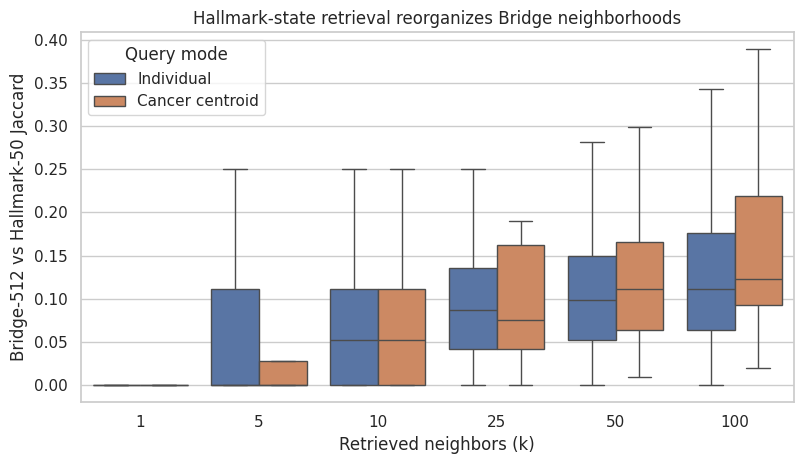

In [3]:
plot_overlap = pd.concat([
    individual.assign(query_mode="Individual"),
    centroid.assign(query_mode="Cancer centroid")
], ignore_index=True)
fig, ax = plt.subplots(figsize=(8.2, 4.8))
sns.boxplot(data=plot_overlap, x="k", y="jaccard", hue="query_mode", showfliers=False, ax=ax)
ax.set(xlabel="Retrieved neighbors (k)", ylabel="Bridge-512 vs Hallmark-50 Jaccard",
       title="Hallmark-state retrieval reorganizes Bridge neighborhoods")
ax.legend(title="Query mode")
savefig(fig, "bridge_hallmark_overlap")

## Functional-profile preservation

Across 32 cancer centroids, the Spearman correlation between each TCGA Hallmark vector and the mean Hallmark vector of its top 100 Hallmark-retrieved ARCHS4 samples was **0.960 at the median** (IQR **0.935–0.975**; range **0.810–0.990**). This verifies that retrieval preserves the coordinates on which it is performed, but it is selection-conditioned and is not independent evidence of shared mechanism.

Pathway-wise preservation was heterogeneous. Apoptosis (`0.978`), Mitotic Spindle (`0.974`), and Hypoxia (`0.972`) were among the strongest across cancers, whereas Myogenesis (`0.814`) and Spermatogenesis (`0.777`) were weaker.

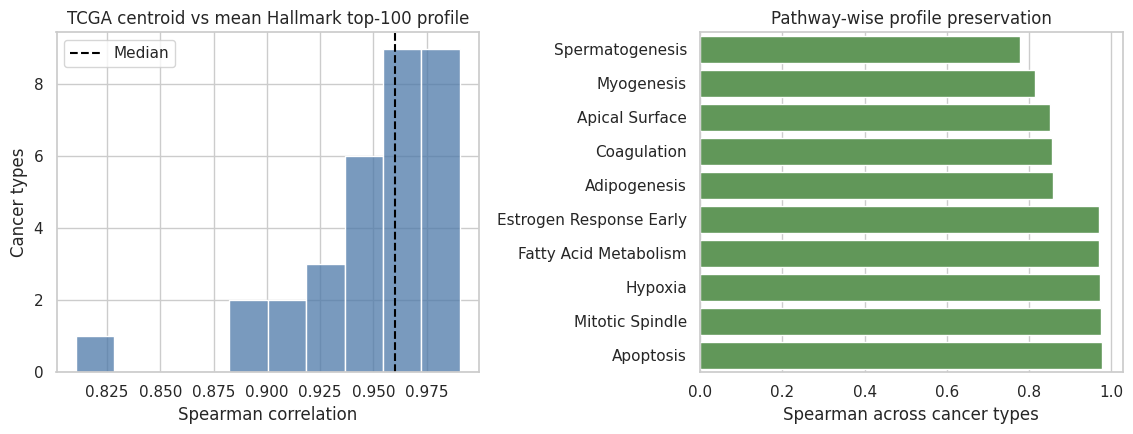

In [4]:
assert np.isclose(preservation.spearman.median(), headline["functional_profile_preservation_spearman_median"])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
sns.histplot(preservation.spearman, bins=10, color="#4C78A8", ax=axes[0])
axes[0].axvline(preservation.spearman.median(), color="black", linestyle="--", label="Median")
axes[0].set(xlabel="Spearman correlation", ylabel="Cancer types",
            title="TCGA centroid vs mean Hallmark top-100 profile")
axes[0].legend()
ordered = pathways.sort_values("spearman_across_cancers")
show = pd.concat([ordered.head(5), ordered.tail(5)]).drop_duplicates()
sns.barplot(data=show, y="hallmark", x="spearman_across_cancers", color="#59A14F", ax=axes[1])
axes[1].set(xlabel="Spearman across cancer types", ylabel="",
            title="Pathway-wise profile preservation")
savefig(fig, "functional_profile_preservation")

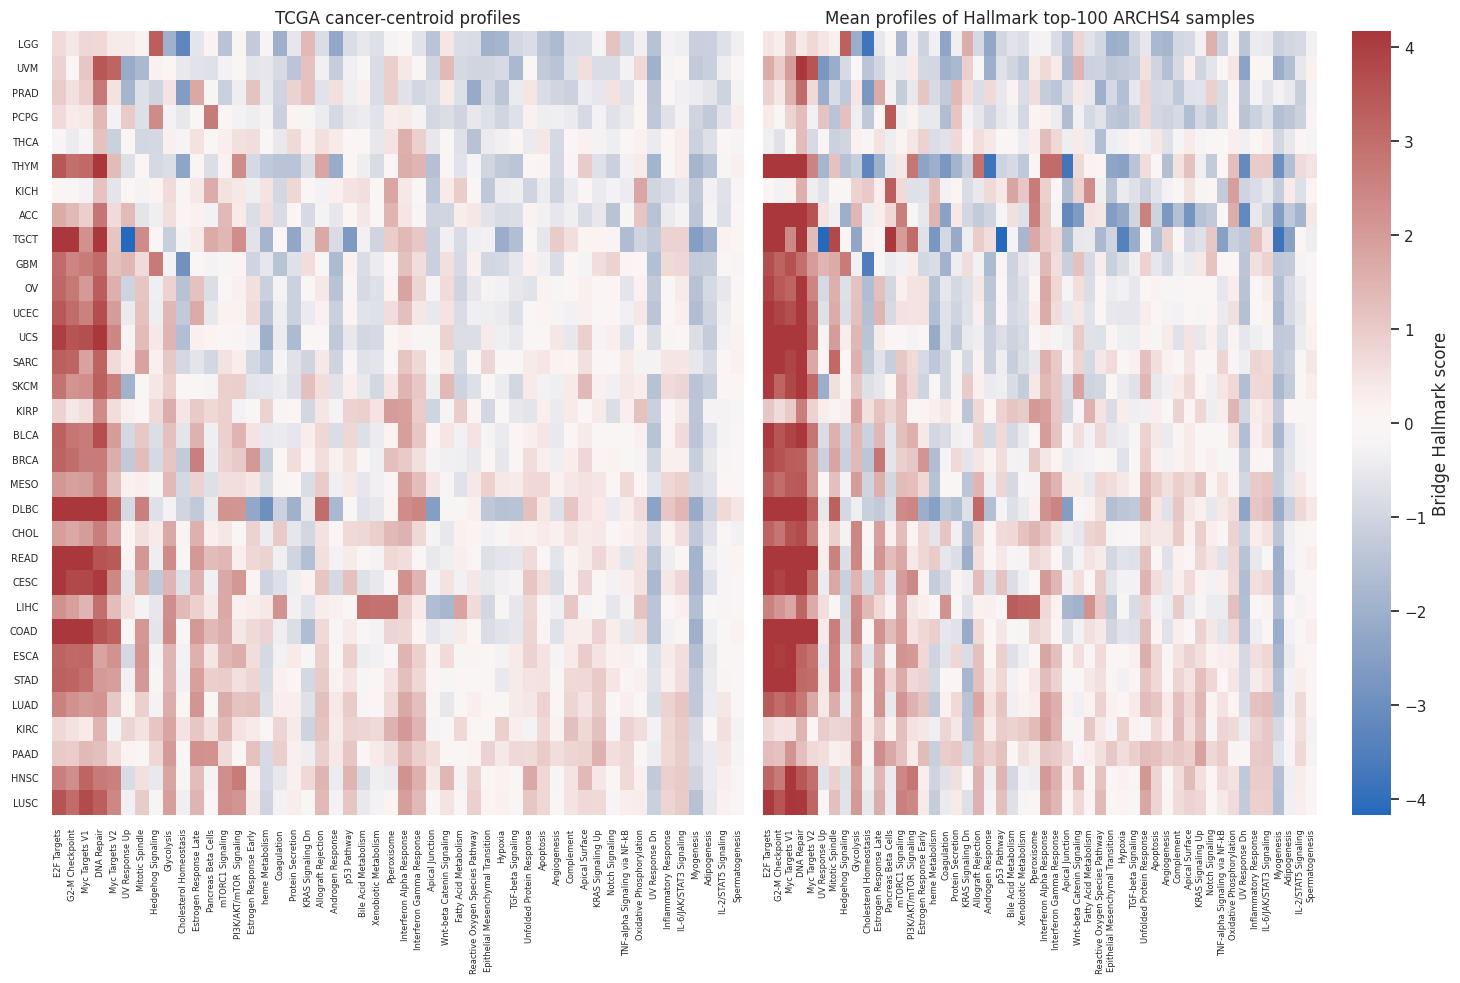

In [5]:
row_order = query_profiles.mean(axis=1).sort_values().index
col_order = query_profiles.var(axis=0).sort_values(ascending=False).index
v = np.nanpercentile(np.abs(np.r_[query_profiles.to_numpy().ravel(), retrieved_profiles.to_numpy().ravel()]), 98)
fig, axes = plt.subplots(1, 2, figsize=(15, 10), sharey=False)
sns.heatmap(query_profiles.loc[row_order, col_order], cmap="vlag", center=0, vmin=-v, vmax=v,
            cbar=False, xticklabels=True, yticklabels=True, ax=axes[0])
sns.heatmap(retrieved_profiles.loc[row_order, col_order], cmap="vlag", center=0, vmin=-v, vmax=v,
            cbar_kws={"label": "Bridge Hallmark score"}, xticklabels=True, yticklabels=False, ax=axes[1])
axes[0].set_title("TCGA cancer-centroid profiles")
axes[1].set_title("Mean profiles of Hallmark top-100 ARCHS4 samples")
for ax in axes:
    ax.tick_params(axis="x", labelsize=6, rotation=90)
    ax.tick_params(axis="y", labelsize=7)
savefig(fig, "centroid_hallmark_profiles")

## Expression baseline and metadata tradeoff

On the common 40,000-sample expression candidate set, median Jaccard@100 was **0.205** for Bridge/expression, **0.156** for Hallmark/expression, and **0.133** for Bridge/Hallmark across the 32 cancer centroids. Expression retrieval was related to both frozen representations but identical to neither.

At individual-query top 100, median organ-keyword agreement was **0.460** for Bridge and **0.400** for Hallmark. Median unique-study counts were **31** and **34**, respectively, and the median maximum single-study fraction was **0.17** for both. Thus Hallmark retrieval does not improve coarse tissue lookup; its value is the alternative functional-program view. ARCHS4 keyword annotations are incomplete free-text proxies rather than biological ground truth.

,comparison,jaccard
0,bridge_vs_expression,0.205
1,bridge_vs_hallmark,0.133
2,hallmark_vs_expression,0.156


,method,organ_keyword_agreement,unique_studies,max_study_fraction
0,bridge512_cosine,0.46,31.0,0.17
1,hallmark50_cosine,0.40,34.0,0.17


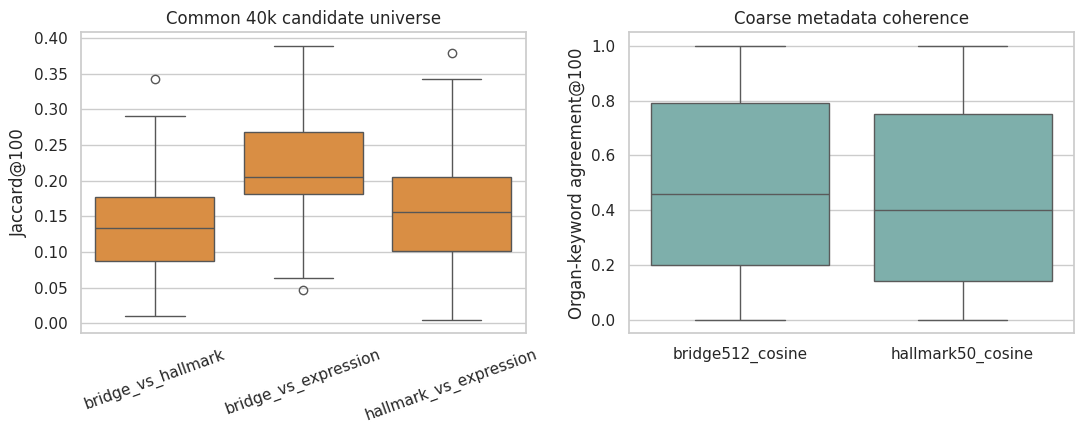

In [6]:
e100 = expression[expression.k.eq(100)]
m100 = metadata[(metadata.query_mode.eq("individual")) & metadata.k.eq(100)]
expr_summary = e100.groupby("comparison", as_index=False).jaccard.median()
meta_summary = m100.groupby("method", as_index=False).agg(
    organ_keyword_agreement=("organ_keyword_agreement", "median"),
    unique_studies=("unique_studies", "median"),
    max_study_fraction=("max_study_fraction", "median")
)
display(expr_summary.round({"jaccard": 3}))
display(meta_summary.round({
    "organ_keyword_agreement": 3, "unique_studies": 0, "max_study_fraction": 2
}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(data=e100, x="comparison", y="jaccard", color="#F28E2B", ax=axes[0])
axes[0].tick_params(axis="x", rotation=20)
axes[0].set(xlabel="", ylabel="Jaccard@100", title="Common 40k candidate universe")
sns.boxplot(data=m100, x="method", y="organ_keyword_agreement", color="#76B7B2", showfliers=False, ax=axes[1])
axes[1].set(xlabel="", ylabel="Organ-keyword agreement@100", title="Coarse metadata coherence")
savefig(fig, "expression_and_metadata_comparison")

## Controls and limitations

- Removing the strongest one or three Hallmark coordinates retained median Jaccard@100 of **0.896** and **0.794**, respectively, although minima of **0.282** and **0.299** show that robustness was not universal.
- The most frequent Bridge and Hallmark database samples appeared in **714** and **663** individual top-100 lists, compared with an approximately **1.92** uniform expectation. Study identity and hub frequency should accompany interpretation of individual matches.
- The ARCHS4 database contains Bridge training, validation, and unseen samples; this is a full-corpus search evaluation rather than a strict unseen-sample test.
- Exact identifier checks found no TCGA/ARCHS4 overlap, but do not rule out biologically duplicated material deposited under unrelated identifiers.
- The expression baseline is restricted to cancer centroids and 40,000 cached candidates.
- Similarity and metadata coherence do not demonstrate shared mechanism, causal pathway activation, or clinical equivalence.

In [7]:
control_summary = dominant.groupby("dimensions_removed", as_index=False).agg(
    median_jaccard=("jaccard", "median"),
    minimum_jaccard=("jaccard", "min"),
    maximum_jaccard=("jaccard", "max")
)
display(control_summary.round({
    "median_jaccard": 3, "minimum_jaccard": 3, "maximum_jaccard": 3
}))
assert np.isclose(control_summary.loc[control_summary.dimensions_removed.eq(1), "median_jaccard"].iloc[0], 0.8957771787960467)
assert np.isclose(control_summary.loc[control_summary.dimensions_removed.eq(3), "median_jaccard"].iloc[0], 0.7937580437580438)
print("All packaged headline metrics reproduce the cached benchmark summaries.")

,dimensions_removed,median_jaccard,minimum_jaccard,maximum_jaccard
0,1,0.896,0.282,1.000
1,3,0.794,0.299,0.923


All packaged headline metrics reproduce the cached benchmark summaries.


## Conclusion

The frozen GTEx-trained Hallmark head converts Bridge sample embeddings into a common 50-dimensional functional-program coordinate system without adapting to TCGA or ARCHS4. Hallmark-50 retrieval preserved the query's predicted pathway profile while returning substantially different ARCHS4 neighborhoods from Bridge-512 and conventional expression retrieval. Bridge better retained coarse organ metadata, whereas Hallmark retrieval supplied a complementary, pathway-decomposable search mode.

The same frozen scaler, Ridge coefficients, Hallmark ordering, Bridge checkpoint, canonical-gene mapping, and preprocessing contract can be carried unchanged into cross-species analyses. Those applications test whether a fixed human-trained pathway coordinate system transfers across species; their biological results and orthology/domain-shift limitations must be evaluated separately.

### References

- Liberzon A. *et al.* The Molecular Signatures Database Hallmark Gene Set Collection. *Cell Systems* (2015).
- Frozen model, cohort, and artifact hashes are recorded in `data/package_provenance.json`.